**Name:** Ankit Kumar<br>
**SAP ID:** 500120442<br>
**Batch:** 02

# Automatic Opinion Summarization from Customer Reviews

Nobody reads 6,000 reviews before buying a pair of headphones. In this project I take a big pile of
real Amazon headphone reviews and let the computer tell me three things:

1. what customers **like** (positive opinions),
2. what customers **dislike** (negative opinions),
3. which **features** people talk about the most (sound, battery, price ...) and how they feel about each one.

My plan in short: clean the text, train a small machine learning model that knows positive from negative,
cut every review into sentences, find the features with POS tagging, and then pick real sentences from the
reviews as the summary.

## Step 0: Install and import the libraries

`nltk` does the language work (sentences, words, POS tags), `scikit-learn` does the machine learning,
`pandas` holds the data as a table and `matplotlib` draws the chart.

In [1]:
%pip install -q nltk scikit-learn pandas matplotlib


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python3.12 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

## Step 1: Load the reviews

The file has real Amazon reviews of headphones and earbuds (taken from the public *Amazon Reviews 2023*
dataset by McAuley Lab). Every row has the product id, the star rating (1 to 5) and the review text.

In [3]:
df = pd.read_csv("data/headphone_reviews.csv")
print("Total reviews:", len(df))
print("Different products:", df["product_id"].nunique())
df[["product_id", "rating", "review"]].head()

Total reviews: 6658
Different products: 4397


,product_id,rating,review
0,B07CJYMRWM,5,I've bought these headphones three times becau...
1,B07BHHB5RH,5,Update 2-they sent a new warranty replacement....
2,B09S6Y5BRG,5,These are fantastic headphones and I love that...
3,B0BN534JBB,5,This has been a great headset for video confer...
4,B09K7K5J3N,5,These are the best and most reasonably priced ...


rating
1     477
2     395
3     679
4    1333
5    3774
Name: count, dtype: int64


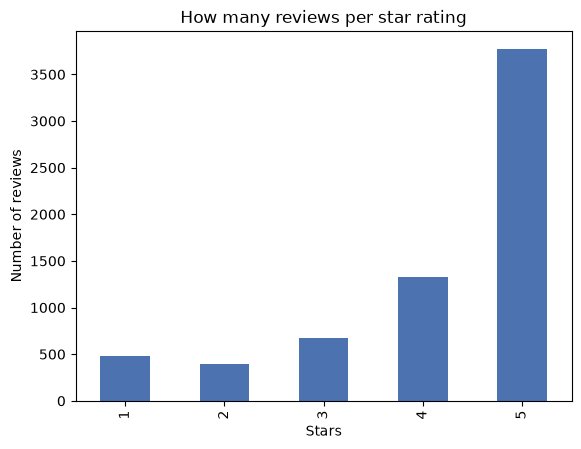

In [4]:
rating_counts = df["rating"].value_counts().sort_index()
print(rating_counts)

rating_counts.plot(kind="bar", color="#4C72B0", title="How many reviews per star rating")
plt.xlabel("Stars")
plt.ylabel("Number of reviews")
plt.savefig("outputs/rating_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

Most people gave 4 or 5 stars, so the data is mostly positive. I keep this in mind later, because a model
trained on it could become lazy and call everything positive.

## Step 2: Clean the text

Real reviews are messy. Some have HTML tags like `<br />`, emojis and strange symbols. My cleaning function
removes the tags, keeps only letters, digits and normal punctuation, and squeezes extra spaces.
I keep the full stops because I need them later to split reviews into sentences.

Example: `"Great sound!<br />Love it 😍"` becomes `"Great sound! Love it"`.

In [5]:
def clean_text(text):
    text = re.sub(r"<.*?>", " ", str(text))              # remove HTML tags like <br />
    text = re.sub(r"[^a-zA-Z0-9.,!?' ]", " ", text)     # keep letters, digits, basic punctuation
    text = re.sub(r"\s+", " ", text)                     # many spaces -> one space
    return text.strip()

df["clean"] = df["review"].apply(clean_text)
print(clean_text("Great sound!<br />Love it 😍"))

Great sound! Love it


## Step 3: Train a sentiment model (machine learning part)

To decide if a sentence is positive or negative I train my own model. The star ratings give me free labels:

* 4 or 5 stars → **positive** (1)
* 1 or 2 stars → **negative** (0)
* 3 stars are mixed, so I leave them out of training.

**TF-IDF** turns each review into numbers: a word gets a high score if it appears in this review but is
not common in every review. I also use word pairs (`ngram_range=(1, 2)`) so the model sees `"not good"`
as one clue, and I do **not** remove stopwords here, because words like "not" and "no" flip the meaning.

**Logistic Regression** then learns a weight for every word: positive weight → positive review.
`class_weight="balanced"` tells it to pay extra attention to the smaller negative class.
I keep 20% of the reviews aside to test the model on reviews it has never seen.

In [6]:
train_df = df[df["rating"] != 3].copy()
train_df["label"] = (train_df["rating"] >= 4).astype(int)    # 1 = positive, 0 = negative

X_train, X_test, y_train, y_test = train_test_split(
    train_df["clean"], train_df["label"], test_size=0.2, random_state=42, stratify=train_df["label"])

vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train_vec, y_train)

predictions = model.predict(X_test_vec)
print("Accuracy on unseen reviews:", round(accuracy_score(y_test, predictions), 3))
print(classification_report(y_test, predictions, target_names=["negative", "positive"]))

Accuracy on unseen reviews: 0.916
              precision    recall  f1-score   support

    negative       0.72      0.70      0.71       174
    positive       0.95      0.95      0.95      1022

    accuracy                           0.92      1196
   macro avg       0.83      0.82      0.83      1196
weighted avg       0.91      0.92      0.92      1196



In [7]:
words = vectorizer.get_feature_names_out()
order = model.coef_[0].argsort()                      # smallest weight first
print("Words that push towards NEGATIVE:", [words[i] for i in order[:12]])
print("Words that push towards POSITIVE:", [words[i] for i in order[-12:]])

Words that push towards NEGATIVE: ['not', 'disappointed', 'poor', 'return', 'returned', 'horrible', 'stopped', 'useless', 'was', 'disappointing', 'back', 'no']
Words that push towards POSITIVE: ['comfortable', 'excellent', 'nice', 'works', 'well', 'for', 'my', 'good', 'easy', 'love', 'and', 'great']


Accuracy is about 92%. The negative class is harder (about 0.71 F1) because there are far fewer negative
reviews to learn from, but the word lists make sense: "disappointed", "poor", "returned", "stopped" are
negative clues, and "great", "love", "comfortable", "perfect" are positive clues.

The model was trained on whole reviews, but I want to use it on single sentences. So let me check a few
sentences I wrote myself:

In [8]:
my_sentences = ["The sound quality is amazing and the bass is deep.",
                "The left earbud stopped working after a week.",
                "They are not comfortable at all.",
                "Great value for the price."]
for s, p in zip(my_sentences, model.predict_proba(vectorizer.transform(my_sentences))[:, 1]):
    print(f"{p:.2f}  {s}")

0.73  The sound quality is amazing and the bass is deep.
0.03  The left earbud stopped working after a week.
0.24  They are not comfortable at all.
0.95  Great value for the price.


The number is the chance of being positive. All four come out the right way, so the model works on sentences too.

## Step 4: Break reviews into sentences and score each sentence

One review often has both feelings: *"Sound is great. But the battery dies in two hours."*
If I scored the whole review I would lose that detail, so I split every review into sentences and
score each one. I skip tiny pieces with fewer than 4 words (like "Wow.").

A sentence is **positive** if the chance is 0.65 or more, **negative** if it is 0.35 or less, and
**neutral** in between (for example "I bought these for the gym.").

In [9]:
def score_sentences(reviews):
    rows = []
    for review_id, text in zip(reviews["review_id"], reviews["clean"]):
        for sentence in nltk.sent_tokenize(text):
            if len(sentence.split()) >= 4:
                rows.append({"review_id": review_id, "sentence": sentence})
    sents = pd.DataFrame(rows)
    sents["pos_prob"] = model.predict_proba(vectorizer.transform(sents["sentence"]))[:, 1]
    sents["sentiment"] = "neutral"
    sents.loc[sents["pos_prob"] >= 0.65, "sentiment"] = "positive"
    sents.loc[sents["pos_prob"] <= 0.35, "sentiment"] = "negative"
    return sents

sentences = score_sentences(df)
print("Total sentences:", len(sentences))
print(sentences["sentiment"].value_counts())
sentences.head()

Total sentences: 39961
sentiment
neutral     21220
positive    15415
negative     3326
Name: count, dtype: int64


,review_id,sentence,pos_prob,sentiment
0,0,I've bought these headphones three times becau...,0.698098,positive
1,0,The sound and bass are awesome.,0.683304,positive
2,0,Hands down my favorite headphones in this pric...,0.694878,positive
3,1,Update 2 they sent a new warranty replacement.,0.377904,neutral
4,1,Update was 5 star until they left headphone di...,0.162980,negative


## Step 5: Find the features people talk about (POS tagging)

Features of a product are almost always **nouns**: sound, battery, price, cable, fit. So I POS tag every
sentence and keep the nouns (tags starting with `NN`). I also turn plurals into singular with a
lemmatizer (`ears` → `ear`) so they are counted together.

Some nouns are very common but are not features, like "headphone", "time", "product" or "son". I put these in a
small hand-made list (`not_features`) and ignore them. Then I simply count in how many sentences each
noun appears; the most frequent ones are the frequently discussed features.

In [10]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()
not_features = {"headphone", "earbuds", "earbud", "headset", "earphone", "bud", "pair", "product",
                "set", "thing", "time", "work", "way", "year", "one", "day", "use", "bit", "lot",
                "review", "something", "month", "week", "people", "star", "end", "brand", "piece",
                "kid", "son", "wife", "daughter", "husband", "hour", "problem", "issue", "phone",
                "iphone", "device", "computer", "player", "music", "life", "feature", "amazon",
                "speaker", "purchase", "order", "item", "anything", "nothing", "everything",
                "reason", "money", "side", "head"}

def get_nouns(sentence):
    tagged = nltk.pos_tag(nltk.word_tokenize(sentence.lower()))
    nouns = set()
    for word, tag in tagged:
        if tag.startswith("NN") and word.isalpha() and len(word) > 2 and word not in stop_words:
            nouns.add(lemmatizer.lemmatize(word))
    return nouns - not_features

sentences["nouns"] = sentences["sentence"].apply(get_nouns)
print(nltk.pos_tag(nltk.word_tokenize("the battery lasts long and the sound is clear")))
print(get_nouns("The batteries last long and the sound is clear"))

[('the', 'DT'), ('battery', 'NN'), ('lasts', 'VBZ'), ('long', 'RB'), ('and', 'CC'), ('the', 'DT'), ('sound', 'NN'), ('is', 'VBZ'), ('clear', 'JJ')]
{'battery', 'sound'}


## Step 6: Link each feature to the opinions about it

For every top feature I take all the sentences that mention it and count how many are positive and how
many are negative. `positive_%` is the share of positive sentences among the positive + negative ones.

In [11]:
def feature_table(sents, top_k=12):
    counts = Counter(noun for nouns in sents["nouns"] for noun in nouns)
    rows = []
    for feature, mentions in counts.most_common(top_k):
        about = sents[sents["nouns"].apply(lambda nouns: feature in nouns)]
        pos = (about["sentiment"] == "positive").sum()
        neg = (about["sentiment"] == "negative").sum()
        rows.append({"feature": feature, "mentions": mentions, "positive": pos,
                     "negative": neg, "positive_%": round(100 * pos / max(pos + neg, 1))})
    return pd.DataFrame(rows).set_index("feature")

features = feature_table(sentences)
features

,mentions,positive,negative,positive_%
feature,,,,
sound,3696,1804,277,87
quality,2805,1433,208,87
ear,2413,832,201,81
price,1515,1059,22,98
noise,1268,552,69,89
case,1054,566,39,94
battery,889,489,44,92
volume,858,265,80,77
bass,805,307,58,84


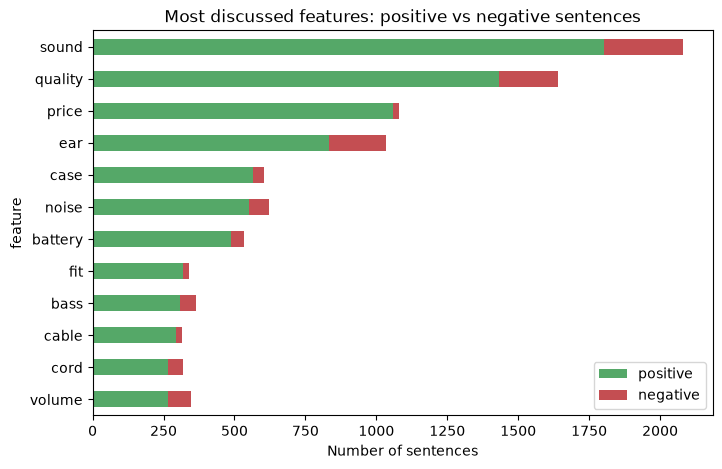

In [12]:
features[["positive", "negative"]].sort_values("positive").plot(
    kind="barh", stacked=True, color=["#55A868", "#C44E52"], figsize=(8, 5),
    title="Most discussed features: positive vs negative sentences")
plt.xlabel("Number of sentences")
plt.savefig("outputs/feature_sentiment.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 7: Write the summary

Now I build the final summary. I do **extractive** summarization, which means I do not invent new text;
I pick the best real sentences written by customers:

* I sort the features by `positive_%`. The top ones (at most 4) are the **liked features**, the bottom
  ones (at most 4, and only if they have at least one negative sentence) are the **disliked features**.
  With few features I take half and half, so one feature never appears in both lists.
* For each liked feature I take the positive sentence the model is most sure about (highest `pos_prob`),
  and for each disliked feature the most clearly negative sentence (lowest `pos_prob`).
  I only use sentences of 6 to 25 words so they are easy to read, and one sentence per feature so the
  summary does not repeat itself.

In [13]:
def best_sentences(sents, sentiment, feature_list):
    picked = []
    for feature in feature_list:
        options = sents[(sents["sentiment"] == sentiment)
                        & sents["nouns"].apply(lambda nouns: feature in nouns)
                        & sents["sentence"].str.split().str.len().between(6, 25)
                        & ~sents["sentence"].isin(picked)]
        if len(options) > 0:
            options = options.sort_values("pos_prob", ascending=(sentiment == "negative"))
            picked.append(options["sentence"].iloc[0])
    return picked

def summarize(reviews, top_k=12):
    sents = score_sentences(reviews)
    sents["nouns"] = sents["sentence"].apply(get_nouns)
    table = feature_table(sents, top_k)
    ranked = table.sort_values("positive_%", ascending=False, kind="stable").index.tolist()
    n = min(4, len(ranked) // 2)                       # at most 4, and never the same feature twice
    liked = ranked[:n]
    disliked = [f for f in ranked[::-1][:n] if table.loc[f, "negative"] > 0]

    print(f"Reviews: {len(reviews)} | Sentences: {len(sents)}")
    print("Frequently discussed features:", ", ".join(table.index))
    print("\nOverall: customers are happiest with the " + ", ".join(liked)
          + ", and complain most about the " + ", ".join(disliked) + ".")
    print("\nPOSITIVE OPINIONS")
    for s in best_sentences(sents, "positive", liked):
        print("  +", s)
    print("\nNEGATIVE OPINIONS")
    for s in best_sentences(sents, "negative", disliked):
        print("  -", s)
    return table

### Summary of all 6,658 headphone reviews

In [14]:
all_table = summarize(df)

Reviews: 6658 | Sentences: 39961
Frequently discussed features: sound, quality, ear, price, noise, case, battery, volume, bass, cord, cable, fit

Overall: customers are happiest with the price, case, cable, fit, and complain most about the volume, ear, cord, bass.

POSITIVE OPINIONS


  + These are great for the price.
  + This is a great carry case for my Sony earbuds and charger.
  + They are easy to charge with just a USB cable.
  + This is a nice set of earbuds, with good sound quality and a comfortable fit.

NEGATIVE OPINIONS
  - Right side earphone doesn't produce the same volume of sound as left side.
  - Just two months after I recieced them, the right ear completely stopped working.
  - but after a few months the cord was getting worn and my left earbud was flickering.
  - The sound out of the one side that work is loud, but not clear at all, and absolutely no bass at all.


### Summary of one single product

The same function works for one product. Here I take the product with the most reviews in my file.

In [15]:
top_product = df["product_id"].value_counts().index[0]
product_reviews = df[df["product_id"] == top_product]
product_table = summarize(product_reviews, top_k=8)
product_table

Reviews: 101 | Sentences: 492
Frequently discussed features: quality, sound, ear, price, battery, volume, charge, noise

Overall: customers are happiest with the price, sound, charge, battery, and complain most about the noise, volume, ear, quality.

POSITIVE OPINIONS
  + These are great headphones for the a good price.
  + The sound quality is great, and it fits comfortably in my ear.
  + They are easy to use, hold a lasting charge, and block out all outside noise.
  + These have excellent sound quality and battery life.

NEGATIVE OPINIONS
  - There is no bass or noise canceling at all.
  - Once finished with the run, I was unable to power off the earphones, pause the music, change the volume or skip forward or back.
  - Also, after working out for about 20 minutes I sweat a lot , the right earphone won't stay in my ear.
  - Every time I buy a new pair, the quality of these get worse and worse.


,mentions,positive,negative,positive_%
feature,,,,
quality,58,26,7,79
sound,49,27,3,90
ear,33,12,4,75
price,19,13,1,93
battery,18,9,2,82
volume,18,3,5,38
charge,11,5,1,83
noise,11,2,4,33


### Try it on your own reviews

Any list of review texts can be summarized. Here are a few short reviews I typed in myself.

In [16]:
my_reviews = ["The sound is crisp and the bass is strong. Battery lasts the whole day easily.",
              "Comfortable fit for long runs. The battery died completely after one month though.",
              "Great sound for the price. The charging case feels cheap and the lid broke.",
              "The bluetooth connection keeps dropping. The sound is good when it works.",
              "Very comfortable fit and the battery life is amazing for the price."]
mine = pd.DataFrame({"review_id": range(len(my_reviews)), "review": my_reviews})
mine["clean"] = mine["review"].apply(clean_text)
my_table = summarize(mine, top_k=6)
my_table

Reviews: 5 | Sentences: 9
Frequently discussed features: sound, battery, fit, price, bass, run

Overall: customers are happiest with the sound, fit, price, and complain most about the battery.

POSITIVE OPINIONS
  + The sound is good when it works.
  + Very comfortable fit and the battery life is amazing for the price.

NEGATIVE OPINIONS
  - The battery died completely after one month though.


,mentions,positive,negative,positive_%
feature,,,,
sound,3,3,0,100
battery,3,1,1,50
fit,2,2,0,100
price,2,2,0,100
bass,1,1,0,100
run,1,1,0,100


## What I learned and the limits

* Star ratings are a cheap way to get labels, and a simple TF-IDF + Logistic Regression model already
  reaches about 92% accuracy on unseen reviews.
* Working at **sentence** level is the key idea: one review can praise the sound and attack the battery,
  and both opinions end up in the right place.
* Frequent nouns are a simple but good way to find features (this is the idea from Hu and Liu, 2004).

Limits I noticed:

* The data is mostly positive, so `positive_%` is high for almost every feature. "Disliked" here means
  *less liked than the others*, not hated.
* A sentence is linked to every feature it mentions, even if the opinion is about only one of them
  ("great sound but bad battery" counts for both).
* The model only knows words it saw in training, and it can miss sarcasm.
* The `not_features` list is made by hand for headphones; a new product type would need a new list.